# 03 Exploratory Data Analysis (EDA)

In diesem Notebook wird der bereinigte Datensatz aus `02_data_cleaning.ipynb` explorativ analysiert.

## Ziele
- Überblick über Struktur und Verteilungen der Daten
- Analyse der Zielvariable `default`
- Untersuchung wichtiger Einflussfaktoren auf Kreditausfälle
- Vergleich von Einkommen, Kredithöhe, Bankguthaben und Score-Werten
- Identifikation relevanter Muster für spätere Modellierung und Scoring-Vergleiche

In [68]:
import os
import io
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [72]:
import os
import io
import pandas as pd

possible_paths = [
    "data/cleaned/credit_score_dataset_cleaned.csv",
    "./data/cleaned/credit_score_dataset_cleaned.csv",
    "/content/data/cleaned/credit_score_dataset_cleaned.csv",
    "credit_score_dataset_cleaned.csv",
    "./credit_score_dataset_cleaned.csv"
]

def load_file_robust(file_bytes, filename="uploaded_file"):
    # 1) Excel-Datei versuchen
    if filename.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(io.BytesIO(file_bytes))

    # 2) CSV mit Standard-Komma
    try:
        return pd.read_csv(io.BytesIO(file_bytes))
    except Exception as e1:
        print("Standard-CSV mit Komma fehlgeschlagen:", e1)

    # 3) CSV mit Semikolon
    try:
        return pd.read_csv(io.BytesIO(file_bytes), sep=";")
    except Exception as e2:
        print("CSV mit Semikolon fehlgeschlagen:", e2)

    # 4) Python-Parser mit Komma
    try:
        return pd.read_csv(io.BytesIO(file_bytes), sep=",", engine="python")
    except Exception as e3:
        print("Python-Parser mit Komma fehlgeschlagen:", e3)

    # 5) Python-Parser mit Semikolon
    try:
        return pd.read_csv(io.BytesIO(file_bytes), sep=";", engine="python")
    except Exception as e4:
        print("Python-Parser mit Semikolon fehlgeschlagen:", e4)

    # 6) Automatische Trennzeichenerkennung
    try:
        return pd.read_csv(io.BytesIO(file_bytes), sep=None, engine="python")
    except Exception as e5:
        print("Automatische Trennzeichenerkennung fehlgeschlagen:", e5)

    raise ValueError(
        "Die Datei konnte weder als CSV noch als Excel-Datei sauber gelesen werden."
    )

file_path = None
for path in possible_paths:
    if os.path.exists(path):
        file_path = path
        break

if file_path is not None:
    df = pd.read_csv(file_path)
    print("Datensatz erfolgreich aus lokalem Pfad geladen.")
    print("Verwendeter Pfad:", file_path)

else:
    print("Keine bereinigte Datei an Standardpfaden gefunden.")
    print("Bitte lade jetzt die bereinigte CSV- oder Excel-Datei manuell hoch.")

    from google.colab import files
    uploaded = files.upload()

    if not uploaded:
        raise FileNotFoundError("Es wurde keine Datei hochgeladen.")

    uploaded_name = list(uploaded.keys())[0]
    uploaded_bytes = uploaded[uploaded_name]

    df = load_file_robust(uploaded_bytes, uploaded_name)

    os.makedirs("data/cleaned", exist_ok=True)
    save_path = "data/cleaned/credit_score_dataset_cleaned.csv"
    df.to_csv(save_path, index=False, encoding="utf-8")

    print("Datensatz erfolgreich aus Upload geladen.")
    print("Hochgeladene Datei:", uploaded_name)
    print("Zusätzlich gespeichert unter:", save_path)

print("Shape:", df.shape)
display(df.head())

Keine bereinigte Datei an Standardpfaden gefunden.
Bitte lade jetzt die bereinigte CSV- oder Excel-Datei manuell hoch.


Saving synthetic_schufa_dataset.csv to synthetic_schufa_dataset.csv
Datensatz erfolgreich aus Upload geladen.
Hochgeladene Datei: synthetic_schufa_dataset.csv
Zusätzlich gespeichert unter: data/cleaned/credit_score_dataset_cleaned.csv
Shape: (10000, 21)


,age,net_income,employment_status,marital_status,dependents,monthly_expenses,existing_loans,credit_amount,debt_to_income,late_payments,hard_inquiries,credit_history_years,negative_entry,collection_cases,bank_balance,liquidity_ratio,old_score,new_score,credit_approved_old_system,credit_approved_new_system,default
0,56,"1,777.140",selbstständig,verheiratet,0,855.640,2,"8,894.400",0.420,0,1,9.200,0,0,"4,301.250",5.030,100.000,100.000,1,1,0
1,69,"3,370.440",teilzeit,verheiratet,0,"1,584.980",1,"19,110.770",0.470,0,0,9.600,0,0,"3,233.970",2.040,100.000,100.000,0,1,0
2,46,"3,558.950",arbeitslos,geschieden,0,"2,547.680",1,"15,440.470",0.360,2,2,10.800,0,0,-409.950,-0.160,93.800,100.000,1,1,1
3,32,"2,230.990",selbstständig,ledig,0,"1,066.700",1,"5,273.970",0.200,0,2,5.600,0,0,"-1,898.470",-1.780,98.600,100.000,1,1,0
4,60,"1,873.870",teilzeit,ledig,1,"1,343.870",3,"8,439.610",0.380,2,1,8.600,0,0,"1,761.980",1.310,96.700,99.400,1,1,0


In [73]:
print("Anzahl Zeilen und Spalten:", df.shape)
print("\nSpaltennamen:")
print(df.columns.tolist())

Anzahl Zeilen und Spalten: (10000, 21)

Spaltennamen:
['age', 'net_income', 'employment_status', 'marital_status', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default']


In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age                         10000 non-null  int64  
 1   net_income                  10000 non-null  float64
 2   employment_status           10000 non-null  object 
 3   marital_status              10000 non-null  object 
 4   dependents                  10000 non-null  int64  
 5   monthly_expenses            10000 non-null  float64
 6   existing_loans              10000 non-null  int64  
 7   credit_amount               10000 non-null  float64
 8   debt_to_income              10000 non-null  float64
 9   late_payments               10000 non-null  int64  
 10  hard_inquiries              10000 non-null  int64  
 11  credit_history_years        10000 non-null  float64
 12  negative_entry              10000 non-null  int64  
 13  collection_cases            1000

In [75]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,"10,000.000",NaN,NaN,NaN,43.539,14.912,18.000,31.000,43.000,56.000,69.000
net_income,"10,000.000",NaN,NaN,NaN,"2,923.520","1,214.299",800.000,"2,043.912","2,874.860","3,745.868","7,034.870"
employment_status,10000,4,angestellt,5761,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital_status,10000,3,ledig,4523,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,"10,000.000",NaN,NaN,NaN,1.073,1.220,0.000,0.000,1.000,2.000,4.000
monthly_expenses,"10,000.000",NaN,NaN,NaN,"1,829.766",856.491,500.000,"1,199.628","1,714.225","2,355.675","5,653.030"
existing_loans,"10,000.000",NaN,NaN,NaN,1.201,1.095,0.000,0.000,1.000,2.000,6.000
credit_amount,"10,000.000",NaN,NaN,NaN,"11,950.006","8,191.213",500.000,"5,380.737","10,250.615","16,868.635","50,000.000"
debt_to_income,"10,000.000",NaN,NaN,NaN,0.353,0.180,0.040,0.200,0.350,0.510,0.670
late_payments,"10,000.000",NaN,NaN,NaN,1.023,1.014,0.000,0.000,1.000,2.000,6.000


In [76]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

missing

,missing_count,missing_percent
age,0,0.000
net_income,0,0.000
employment_status,0,0.000
marital_status,0,0.000
dependents,0,0.000
monthly_expenses,0,0.000
existing_loans,0,0.000
credit_amount,0,0.000
debt_to_income,0,0.000
late_payments,0,0.000


In [77]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerische Spalten:")
print(numeric_cols)

print("\nKategorische Spalten:")
print(categorical_cols)

Numerische Spalten:
['age', 'net_income', 'dependents', 'monthly_expenses', 'existing_loans', 'credit_amount', 'debt_to_income', 'late_payments', 'hard_inquiries', 'credit_history_years', 'negative_entry', 'collection_cases', 'bank_balance', 'liquidity_ratio', 'old_score', 'new_score', 'credit_approved_old_system', 'credit_approved_new_system', 'default']

Kategorische Spalten:
['employment_status', 'marital_status']


In [78]:
df["default"].value_counts(dropna=False)

,count
default,
0,8699
1,1301


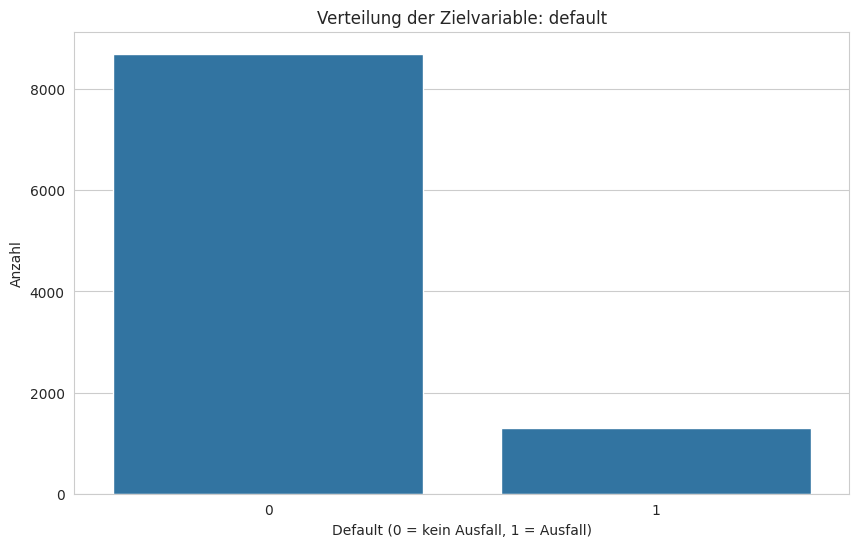

In [79]:
sns.countplot(data=df, x="default")
plt.title("Verteilung der Zielvariable: default")
plt.xlabel("Default (0 = kein Ausfall, 1 = Ausfall)")
plt.ylabel("Anzahl")
plt.show()

## Interpretation der Zielvariable

Hier siehst du, wie stark die Zielvariable verteilt ist.  
Falls `default = 1` deutlich seltener ist, hast du ein Klassenungleichgewicht.  
Das ist später für das Modelltraining wichtig.

In [80]:
main_numeric_cols = [
    "age",
    "net_income",
    "monthly_expenses",
    "existing_loans",
    "credit_amount",
    "debt_to_income",
    "late_payments",
    "hard_inquiries",
    "credit_history_years",
    "collection_cases",
    "bank_balance",
    "liquidity_ratio",
    "old_score",
    "new_score",
    "debt_to_income_clean",
    "expense_to_income_ratio",
    "balance_to_income_ratio"
]

main_numeric_cols = [col for col in main_numeric_cols if col in df.columns]
main_numeric_cols

['age',
 'net_income',
 'monthly_expenses',
 'existing_loans',
 'credit_amount',
 'debt_to_income',
 'late_payments',
 'hard_inquiries',
 'credit_history_years',
 'collection_cases',
 'bank_balance',
 'liquidity_ratio',
 'old_score',
 'new_score']

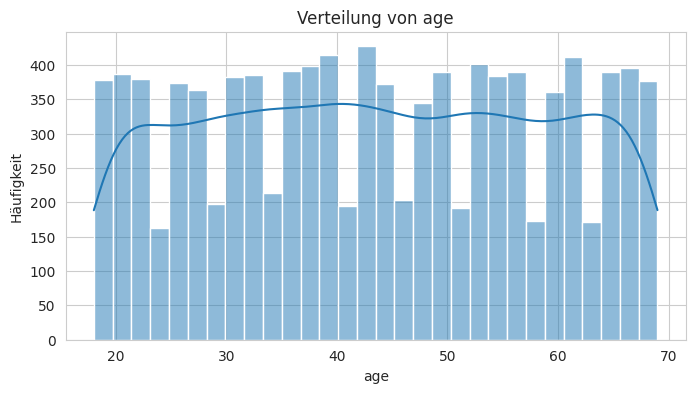

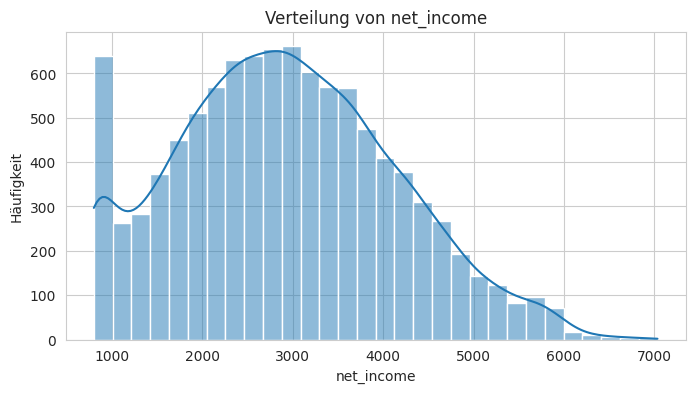

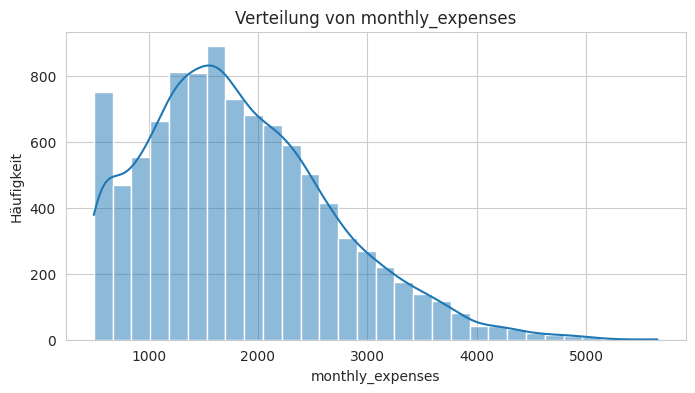

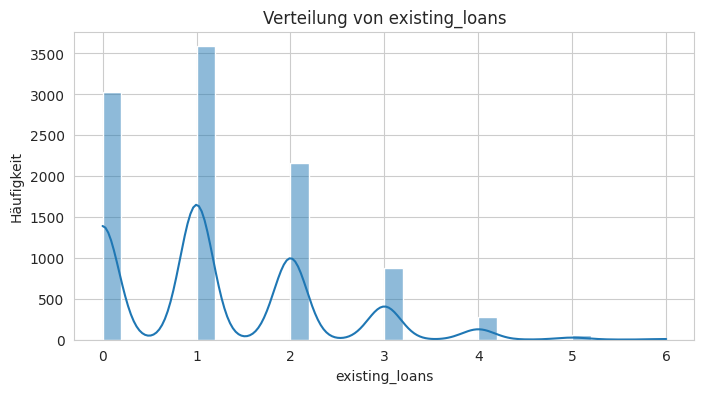

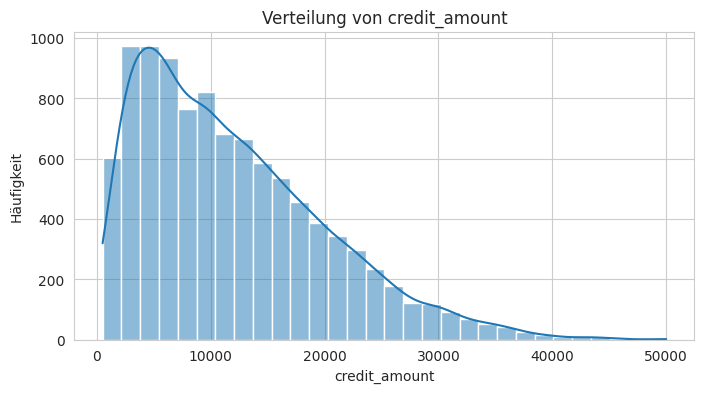

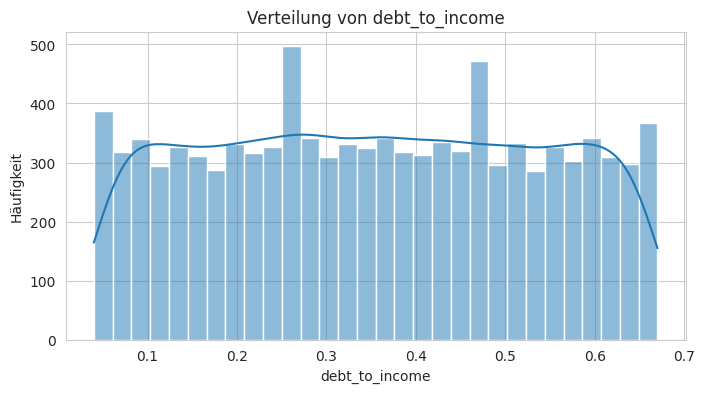

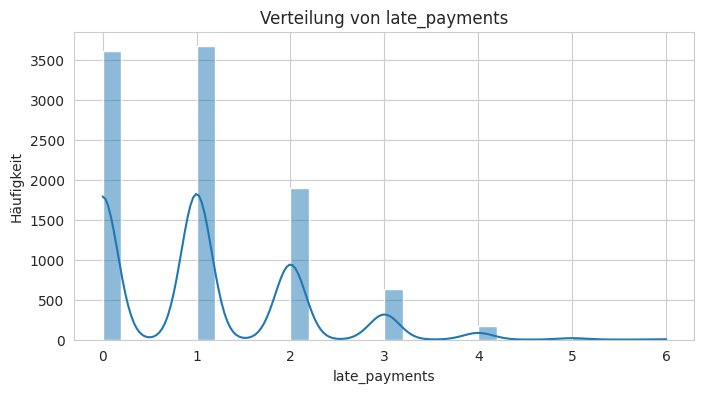

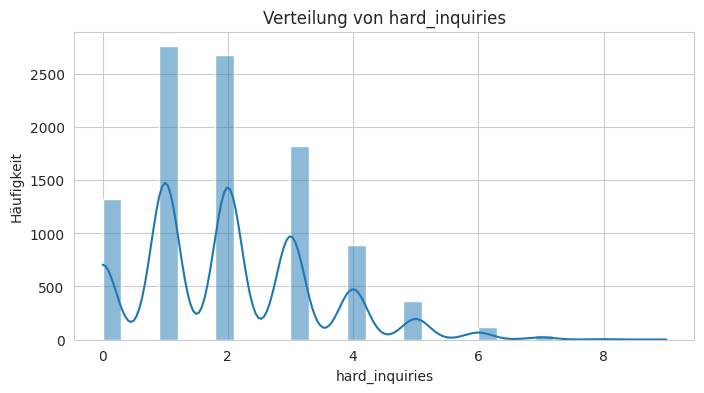

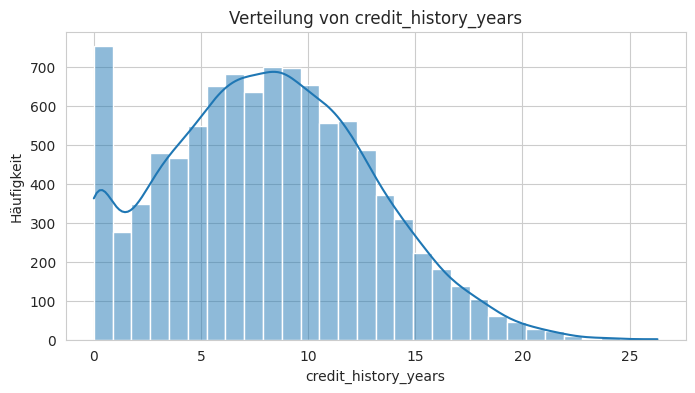

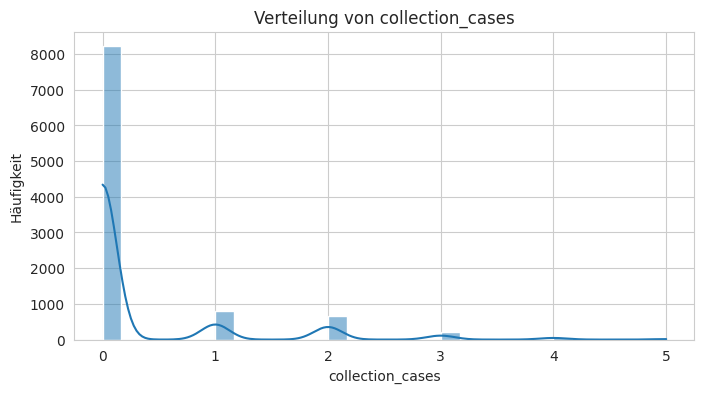

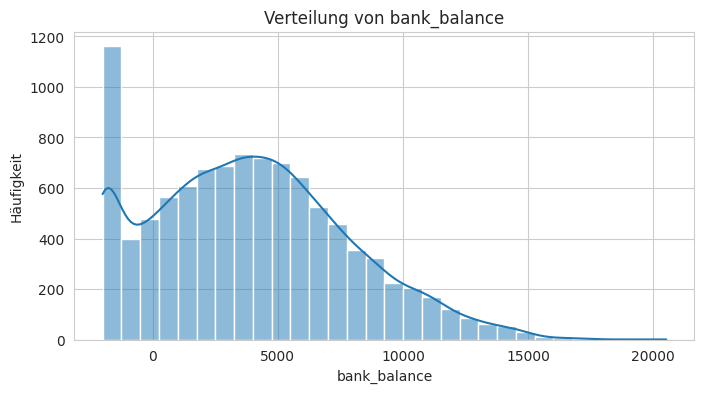

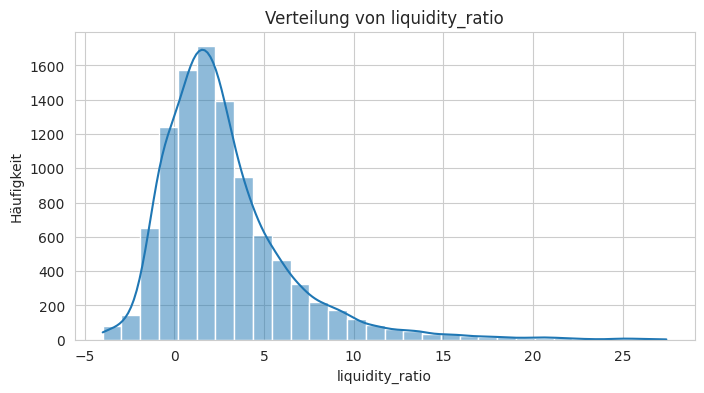

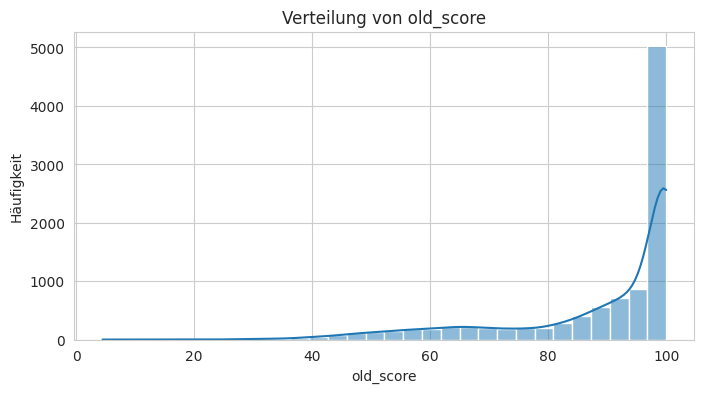

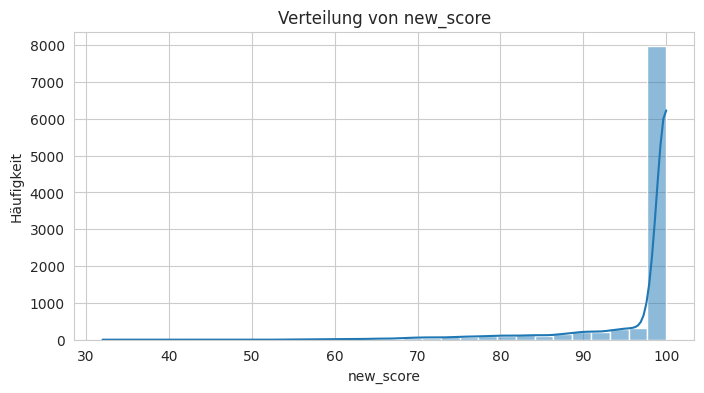

In [81]:
for col in main_numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f"Verteilung von {col}")
    plt.xlabel(col)
    plt.ylabel("Häufigkeit")
    plt.show()

In [82]:
for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- employment_status ---
employment_status
angestellt       5761
selbstständig    1770
teilzeit         1678
arbeitslos        791
Name: count, dtype: int64

--- marital_status ---
marital_status
ledig          4523
verheiratet    3996
geschieden     1481
Name: count, dtype: int64


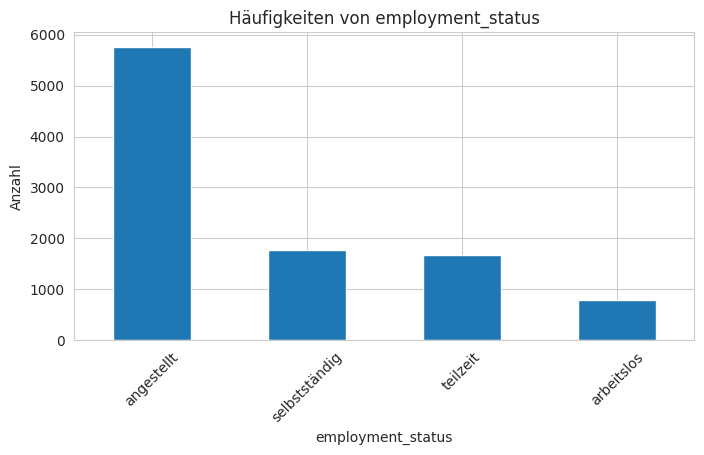

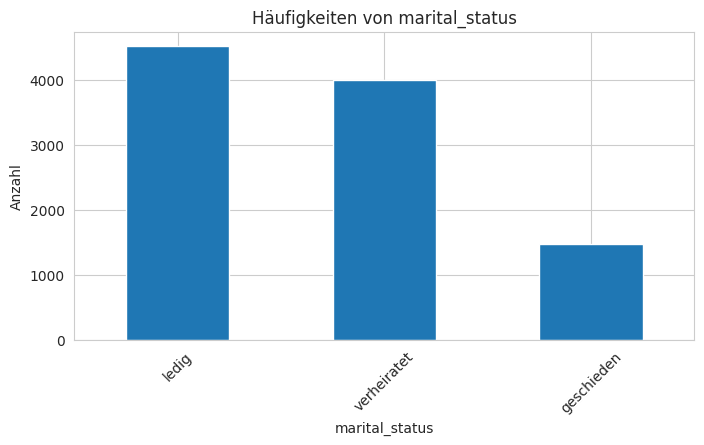

In [83]:
for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    df[col].value_counts(dropna=False).plot(kind="bar")
    plt.title(f"Häufigkeiten von {col}")
    plt.xlabel(col)
    plt.ylabel("Anzahl")
    plt.xticks(rotation=45)
    plt.show()

In [84]:
df.groupby("default")[main_numeric_cols].mean().T

default,0,1
age,43.477,43.955
net_income,"2,958.600","2,688.963"
monthly_expenses,"1,858.045","1,640.682"
existing_loans,1.197,1.232
credit_amount,"11,826.470","12,776.013"
debt_to_income,0.344,0.413
late_payments,0.998,1.191
hard_inquiries,2.009,1.957
credit_history_years,8.136,8.246
collection_cases,0.277,0.630


In [85]:
df.groupby("default")[main_numeric_cols].median().T

default,0,1
age,43.000,44.000
net_income,"2,913.550","2,519.670"
monthly_expenses,"1,748.230","1,497.120"
existing_loans,1.000,1.000
credit_amount,"10,220.790","10,596.020"
debt_to_income,0.340,0.460
late_payments,1.000,1.000
hard_inquiries,2.000,2.000
credit_history_years,8.100,8.100
collection_cases,0.000,0.000


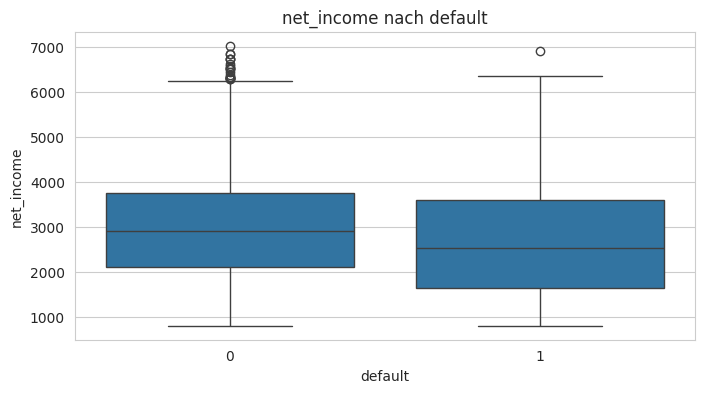

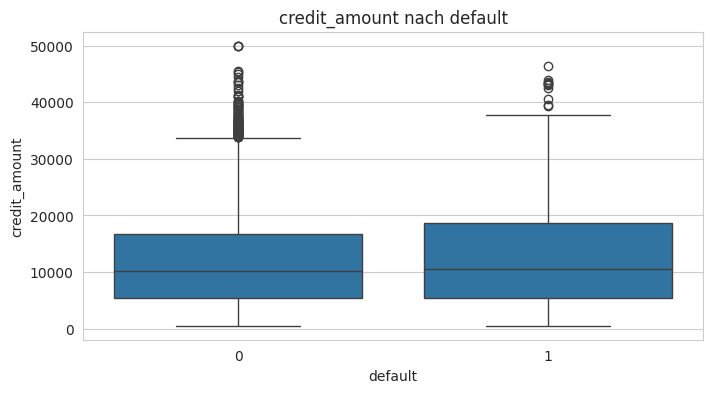

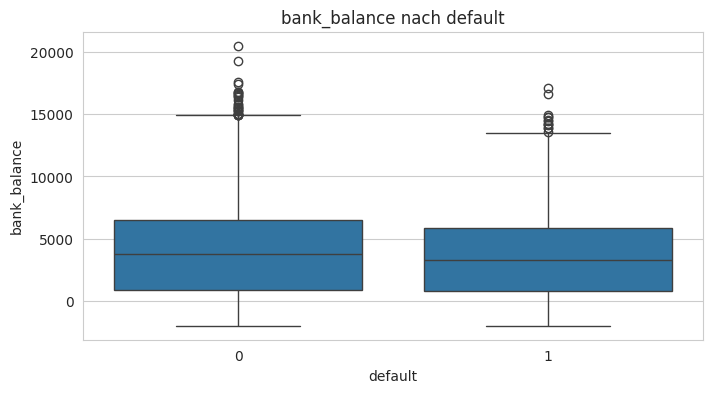

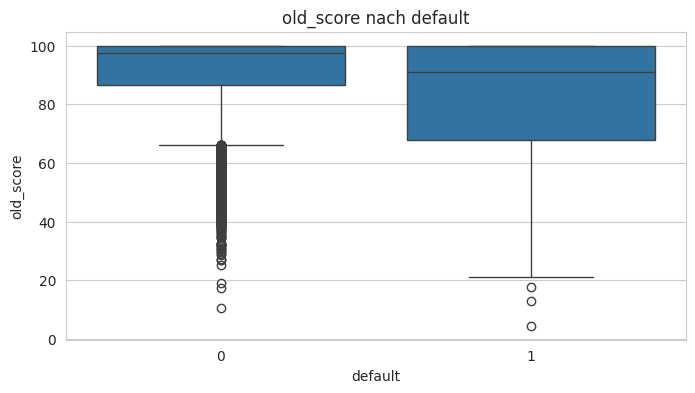

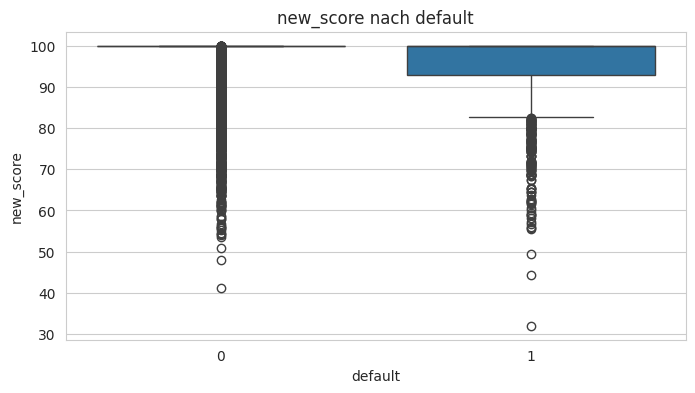

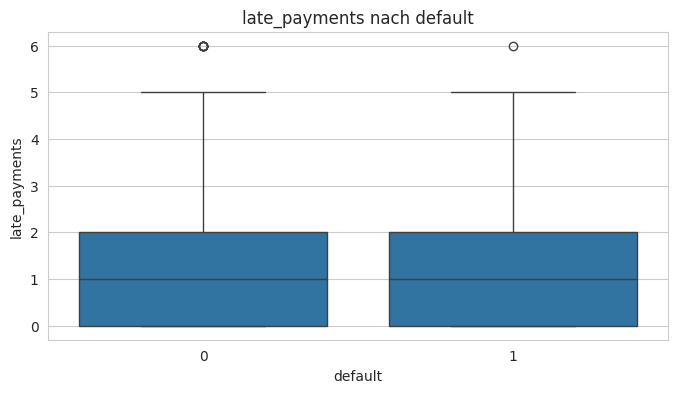

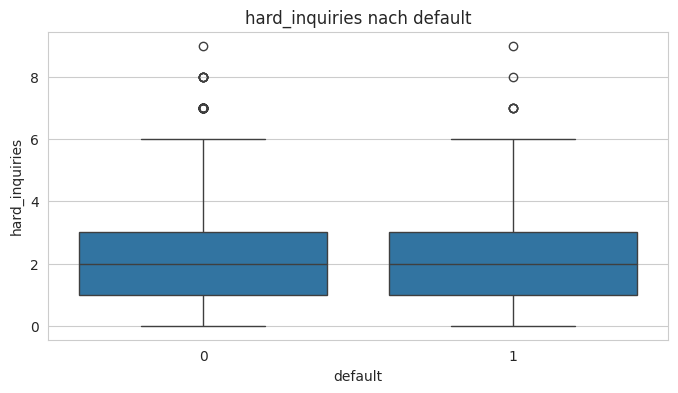

In [86]:
compare_cols = [
    "net_income",
    "credit_amount",
    "bank_balance",
    "old_score",
    "new_score",
    "debt_to_income_clean",
    "expense_to_income_ratio",
    "balance_to_income_ratio",
    "late_payments",
    "hard_inquiries"
]

compare_cols = [col for col in compare_cols if col in df.columns]

for col in compare_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="default", y=col)
    plt.title(f"{col} nach default")
    plt.xlabel("default")
    plt.ylabel(col)
    plt.show()

In [87]:
if "debt_to_income_clean" in df.columns:
    sns.histplot(df["debt_to_income_clean"], bins=30, kde=True)
    plt.title("Verteilung von debt_to_income_clean")
    plt.xlabel("Debt-to-Income")
    plt.show()

In [88]:
if "debt_to_income_clean" in df.columns:
    sns.boxplot(data=df, x="default", y="debt_to_income_clean")
    plt.title("Debt-to-Income nach default")
    plt.xlabel("default")
    plt.ylabel("debt_to_income_clean")
    plt.show()

In [89]:
if {"income_group", "credit_amount"}.issubset(df.columns):
    display(
        df.groupby("income_group")["credit_amount"]
        .agg(["count", "mean", "median", "min", "max"])
        .round(2)
    )

In [90]:
special_flags = [
    "high_income_negative_entry",
    "high_liquidity_negative_entry",
    "high_income_high_liquidity_negative_entry"
]

for col in special_flags:
    if col in df.columns:
        print(f"\n--- {col} ---")
        print(df[col].value_counts(dropna=False))
        print("\nDefault-Rate in dieser Gruppe:")
        print((df.groupby(col)["default"].mean() * 100).round(2))

In [91]:
if "high_income_high_liquidity_negative_entry" in df.columns:
    subset = df[df["high_income_high_liquidity_negative_entry"] == 1]

    print("Anzahl Fälle:", len(subset))

    cols_to_show = [
        "net_income",
        "bank_balance",
        "negative_entry",
        "old_score",
        "new_score",
        "credit_amount",
        "debt_to_income_clean",
        "default"
    ]
    cols_to_show = [c for c in cols_to_show if c in df.columns]

    display(subset[cols_to_show].head(20))

## Fachliche Bedeutung

Diese Gruppe ist für das Projekt besonders wichtig:

- negative Schufa-/Bonitätshistorie
- aber gleichzeitig hohes Einkommen
- und/oder hohe Liquidität

Wenn die Ausfallrate dieser Personen nicht extrem hoch ist, dann ist das ein starkes Argument:
Ein Score oder Negativmerkmal allein bildet reale Zahlungsfähigkeit nicht vollständig ab.

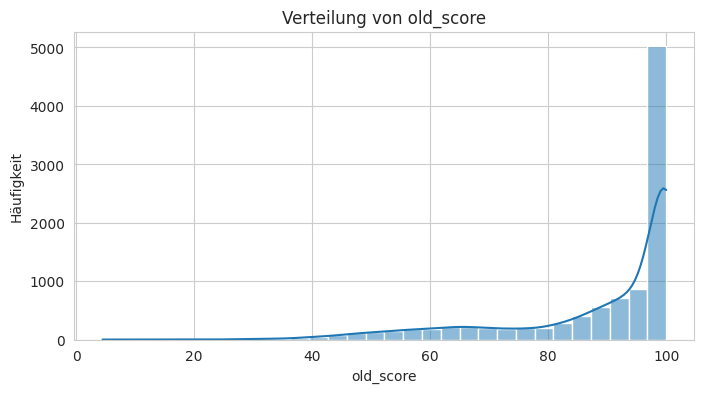

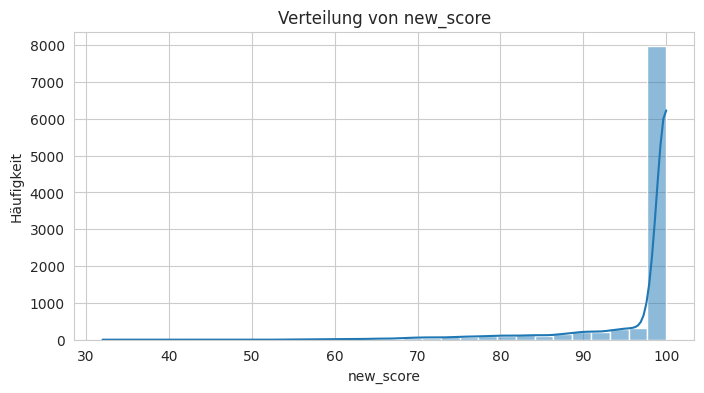

In [92]:
score_cols = [col for col in ["old_score", "new_score"] if col in df.columns]

for col in score_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"Verteilung von {col}")
    plt.xlabel(col)
    plt.ylabel("Häufigkeit")
    plt.show()

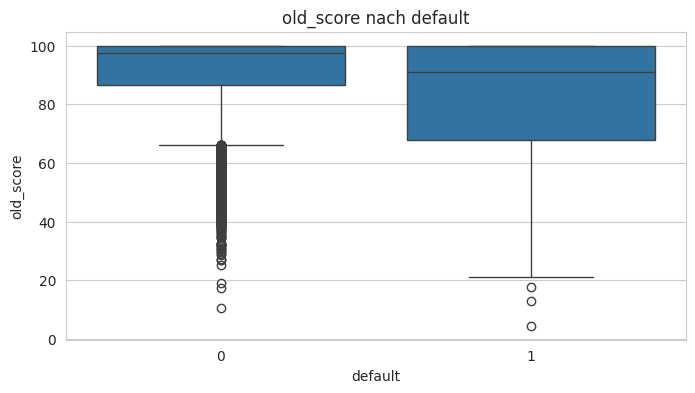

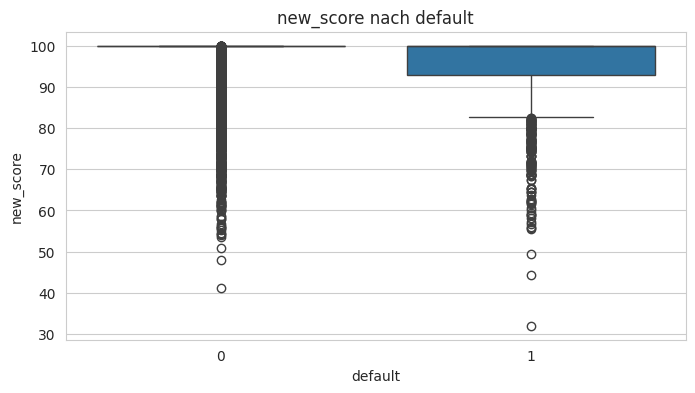

In [93]:
for col in score_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="default", y=col)
    plt.title(f"{col} nach default")
    plt.xlabel("default")
    plt.ylabel(col)
    plt.show()

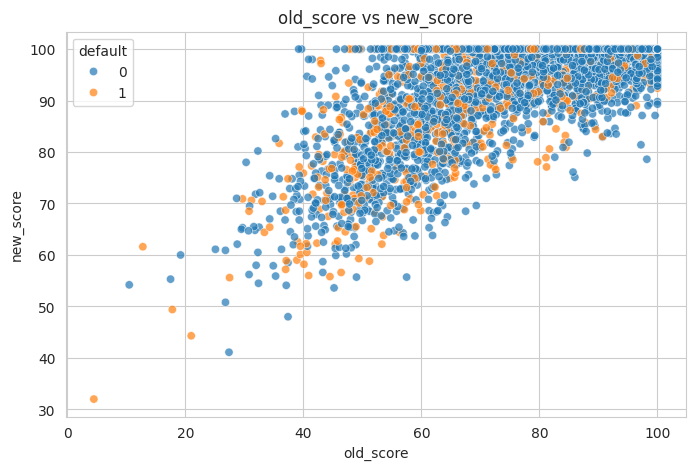

In [94]:
if {"old_score", "new_score"}.issubset(df.columns):
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x="old_score", y="new_score", hue="default", alpha=0.7)
    plt.title("old_score vs new_score")
    plt.xlabel("old_score")
    plt.ylabel("new_score")
    plt.show()

In [100]:
approval_cols = [
    "credit_approved_old_system_clean",
    "credit_approved_new_system_clean"
]

approval_cols = [col for col in approval_cols if col in df.columns]

for col in approval_cols:
    print(f"\n--- {col} ---")
    print((df[col].value_counts(normalize=True) * 100).round(2))

In [101]:
if {"credit_approved_old_system_clean", "credit_approved_new_system_clean"}.issubset(df.columns):
    comparison = pd.crosstab(
        df["credit_approved_old_system_clean"],
        df["credit_approved_new_system_clean"],
        rownames=["old_system"],
        colnames=["new_system"]
    )
    comparison

In [102]:
corr_cols = [
    "net_income",
    "monthly_expenses",
    "credit_amount",
    "debt_to_income_clean",
    "bank_balance",
    "liquidity_ratio",
    "old_score",
    "new_score",
    "late_payments",
    "hard_inquiries",
    "collection_cases",
    "default"
]

corr_cols = [col for col in corr_cols if col in df.columns]
corr = df[corr_cols].corr()
corr

,net_income,monthly_expenses,credit_amount,bank_balance,liquidity_ratio,old_score,new_score,late_payments,hard_inquiries,collection_cases,default
net_income,1.000,0.775,0.533,0.103,-0.223,-0.131,-0.028,0.002,0.005,0.111,-0.075
monthly_expenses,0.775,1.000,0.507,-0.017,-0.378,-0.001,-0.037,-0.000,0.005,-0.008,-0.085
credit_amount,0.533,0.507,1.000,-0.007,-0.215,-0.051,-0.043,0.004,0.010,0.005,0.039
bank_balance,0.103,-0.017,-0.007,1.000,0.780,-0.136,0.137,0.011,-0.002,0.115,-0.033
liquidity_ratio,-0.223,-0.378,-0.215,0.780,1.000,-0.104,0.157,-0.002,-0.011,0.094,0.023
old_score,-0.131,-0.001,-0.051,-0.136,-0.104,1.000,0.766,-0.161,-0.119,-0.828,-0.154
new_score,-0.028,-0.037,-0.043,0.137,0.157,0.766,1.000,-0.109,-0.085,-0.698,-0.131
late_payments,0.002,-0.000,0.004,0.011,-0.002,-0.161,-0.109,1.000,-0.005,-0.007,0.064
hard_inquiries,0.005,0.005,0.010,-0.002,-0.011,-0.119,-0.085,-0.005,1.000,0.005,-0.012
collection_cases,0.111,-0.008,0.005,0.115,0.094,-0.828,-0.698,-0.007,0.005,1.000,0.150


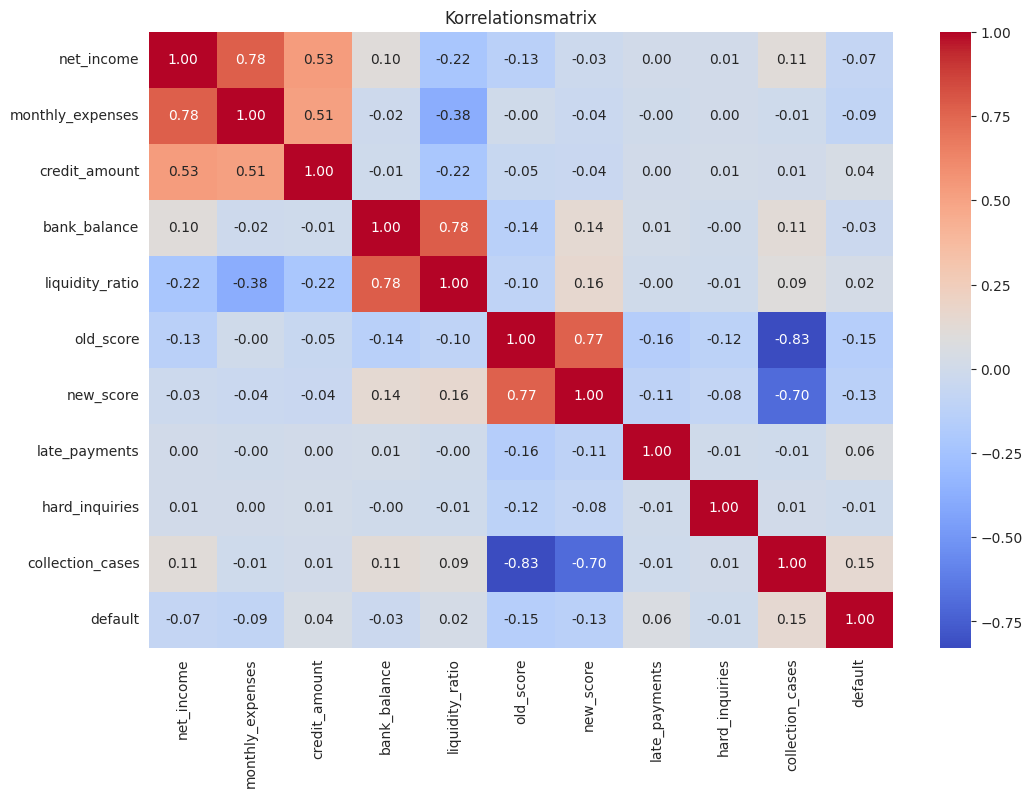

In [98]:
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korrelationsmatrix")
plt.show()

In [103]:
plot_pairs = [
    ("net_income", "credit_amount"),
    ("net_income", "bank_balance"),
    ("old_score", "credit_amount"),
    ("new_score", "credit_amount")
]

valid_pairs = [(x, y) for x, y in plot_pairs if x in df.columns and y in df.columns]
valid_pairs

[('net_income', 'credit_amount'),
 ('net_income', 'bank_balance'),
 ('old_score', 'credit_amount'),
 ('new_score', 'credit_amount')]

In [104]:
cat_analysis_cols = [
    "employment_status",
    "marital_status",
    "income_group",
    "age_group"
]

cat_analysis_cols = [col for col in cat_analysis_cols if col in df.columns]

for col in cat_analysis_cols:
    print(f"\n--- Default-Anteile nach {col} ---")
    result = pd.crosstab(df[col], df["default"], normalize="index") * 100
    display(result.round(2))


--- Default-Anteile nach employment_status ---


default,0,1
employment_status,,
angestellt,87.050,12.950
arbeitslos,85.210,14.790
selbstständig,87.800,12.200
teilzeit,86.770,13.230



--- Default-Anteile nach marital_status ---


default,0,1
marital_status,,
geschieden,87.040,12.960
ledig,86.730,13.270
verheiratet,87.260,12.740


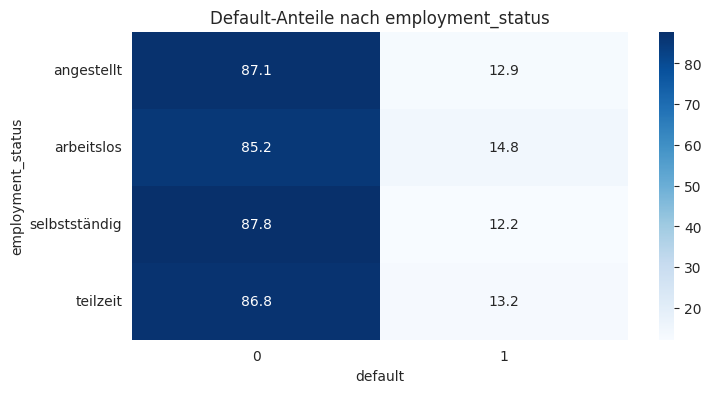

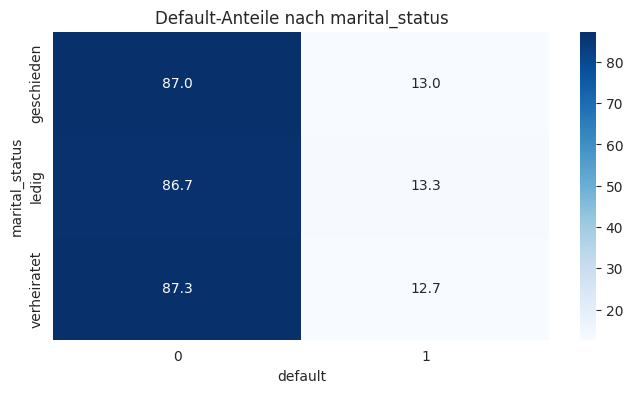

In [105]:
for col in cat_analysis_cols:
    result = pd.crosstab(df[col], df["default"], normalize="index") * 100
    plt.figure(figsize=(8, 4))
    sns.heatmap(result, annot=True, fmt=".1f", cmap="Blues")
    plt.title(f"Default-Anteile nach {col}")
    plt.show()

In [106]:
summary = {
    "rows": len(df),
    "columns": df.shape[1],
    "default_rate_percent": round(df["default"].mean() * 100, 2) if "default" in df.columns else None,
    "avg_net_income": round(df["net_income"].mean(), 2) if "net_income" in df.columns else None,
    "avg_credit_amount": round(df["credit_amount"].mean(), 2) if "credit_amount" in df.columns else None,
    "avg_bank_balance": round(df["bank_balance"].mean(), 2) if "bank_balance" in df.columns else None,
    "avg_old_score": round(df["old_score"].mean(), 2) if "old_score" in df.columns else None,
    "avg_new_score": round(df["new_score"].mean(), 2) if "new_score" in df.columns else None
}

pd.DataFrame(summary.items(), columns=["Kennzahl", "Wert"])

,Kennzahl,Wert
0,rows,"10,000.000"
1,columns,21.000
2,default_rate_percent,13.010
3,avg_net_income,"2,923.520"
4,avg_credit_amount,"11,950.010"
5,avg_bank_balance,"3,883.070"
6,avg_old_score,89.120
7,avg_new_score,97.110


In [107]:
import os

os.makedirs("data/cleaned", exist_ok=True)

output_path = "data/cleaned/credit_score_dataset_cleaned.csv"
df.to_csv(output_path, index=False, encoding="utf-8")

print("Datei gespeichert unter:", output_path)
print("Absoluter Pfad:", os.path.abspath(output_path))
print("Existiert:", os.path.exists(output_path))

Datei gespeichert unter: data/cleaned/credit_score_dataset_cleaned.csv
Absoluter Pfad: /content/data/cleaned/credit_score_dataset_cleaned.csv
Existiert: True


# Zentrale Erkenntnisse aus der EDA

## 1. Datenbasis
Der bereinigte Datensatz enthält die zentralen Kredit-, Einkommens-, Liquiditäts- und Score-Variablen aus dem vorherigen Notebook.

## 2. Zielvariable
Die Verteilung von `default` zeigt, wie häufig Kreditausfälle vorkommen und ob ein Klassenungleichgewicht vorliegt.

## 3. Finanzielle Belastung
Für das Ausfallrisiko sind nicht nur Einkommen oder Kredithöhe einzeln relevant, sondern vor allem ihr Verhältnis über `debt_to_income_clean`.

## 4. Score-Systeme
Die Verteilungen von `old_score` und `new_score` sowie ihr Zusammenhang mit `default` liefern erste Hinweise auf die Trennschärfe beider Systeme.

## 5. Kritische Spezialfälle
Die Gruppen mit negativer Historie, aber gleichzeitig hohem Einkommen und/oder hoher Liquidität, sind für die Projektstory besonders wichtig.
Sie können zeigen, dass pauschale Negativmerkmale reale Zahlungsfähigkeit nicht vollständig abbilden.

## 6. Nächste Schritte
Diese EDA bereitet die Scoring-Vergleiche, Default-Modelle, Modellinterpretation und Fairness-/Business-Impact-Analyse vor.

# Nächster Schritt

Im nächsten Notebook kann auf Basis dieser EDA analysiert werden:

- wie sich `old_score` und `new_score` systematisch unterscheiden,
- wie sich Kreditentscheidungen verändern,
- und welche Gruppen durch das neue System profitieren oder benachteiligt werden.

